Shape matching y mapas funcionales
## Tutorial práctico: del matching isométrico a los *functional maps*, ICP espectral y ZoomOut

**CC5513 Procesamiento Geométrico y Análisis de Formas** · Ivan Sipiran · DCC, Universidad de Chile

Dadas dos formas $\mathcal M$ y $\mathcal N$, queremos un mapa $T:\mathcal N\to\mathcal M$ que
lleve cada punto de una a su punto "equivalente" en la otra. Con un buen mapa podemos transferir
texturas, segmentaciones y deformaciones. En este tutorial:

| Bloque | Tema | Ejercicios | Tiempo |
|---|---|---|---|
| 0 | Preparación: un par de formas con groundtruth | — | 10 min |
| 1 | Matching isométrico: distorsión geodésica (2–8) | 1–2 | 30 min |
| 2 | **El mapa funcional**: $T\mapsto T_F\mapsto\mathbf C$ (9–19) | 3–5 | 40 min |
| 3 | De $\mathbf C$ a un mapa punto a punto (20) | 6 | 15 min |
| 4 | **Estimar $\mathbf C$** sin conocer el mapa (Ovsjanikov et al., 2012) | 7 | 40 min |
| 5 | Refinamiento: **ICP espectral** y **ZoomOut** | 8–9 | 30 min |
| 6 | Todo junto en otra forma; simetrías | — | 10 min |
| 7 | Cierre y preguntas | — | 5 min |

**Cómo trabajar.** Cada ejercicio tiene una celda con `TODO` y una celda de tests con `assert`.
Las soluciones están plegadas al final del notebook. Todo corre en Colab sin GPU ni descargas
(NumPy, SciPy, Matplotlib y scikit-image). La ejecución completa toma unos 2 minutos.

**Convenciones.** Como en el tutorial anterior: $\mathbf L$ es el Laplaciano de cotangentes (semidefinido
positivo), $\mathbf M$ la matriz de masa, $\mathbf L\boldsymbol\Phi=\mathbf M\boldsymbol\Phi\boldsymbol\Lambda$
con $\boldsymbol\Phi^\top\mathbf M\boldsymbol\Phi=\mathbf I$. Un **mapa punto a punto**
$T:\mathcal N\to\mathcal M$ se guarda como un arreglo `T` de largo $n_{\mathcal N}$: `T[y]` es el
índice del vértice de $\mathcal M$ que le corresponde al vértice `y` de $\mathcal N$.

---
# Bloque 0 — Preparación (10 min)

La primera celda trae las utilidades de la Clase 13 (mallas, Laplaciano, criaturas sintéticas,
renderizador, espectro, WKS, kernel de calor) y algunas nuevas: búsqueda de vecino más cercano,
muestreo del punto más lejano y un evaluador de mapas.

In [34]:
#@title Utilidades de la clase (ejecutar sin modificar — doble clic para ver el código)
# Parte 1: mallas, Laplaciano, criaturas sintéticas y visualización (las mismas de la Clase 13)
import time, warnings
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as sla
import scipy.linalg as sl
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib import colors as mcolors
from skimage.measure import marching_cubes

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': False})

# ------------------------------------------------------------------
# 1. Mallas básicas
# ------------------------------------------------------------------
def edges_of(F):
    """Aristas únicas (i<j) de una malla triangular."""
    E = np.sort(np.vstack([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), 1)
    return np.unique(E, axis=0)

def euler_characteristic(V, F):
    return len(V) - len(edges_of(F)) + len(F)

def face_areas(V, F):
    return 0.5 * np.linalg.norm(np.cross(V[F[:, 1]] - V[F[:, 0]], V[F[:, 2]] - V[F[:, 0]]), axis=1)

def icosphere(level=4):
    """Esfera unitaria por subdivisión de un icosaedro (10·4^level + 2 vértices)."""
    t = (1 + 5 ** .5) / 2
    V = np.array([[-1, t, 0], [1, t, 0], [-1, -t, 0], [1, -t, 0], [0, -1, t], [0, 1, t],
                  [0, -1, -t], [0, 1, -t], [t, 0, -1], [t, 0, 1], [-t, 0, -1], [-t, 0, 1]], float)
    F = np.array([[0, 11, 5], [0, 5, 1], [0, 1, 7], [0, 7, 10], [0, 10, 11], [1, 5, 9], [5, 11, 4],
                  [11, 10, 2], [10, 7, 6], [7, 1, 8], [3, 9, 4], [3, 4, 2], [3, 2, 6], [3, 6, 8],
                  [3, 8, 9], [4, 9, 5], [2, 4, 11], [6, 2, 10], [8, 6, 7], [9, 8, 1]])
    V /= np.linalg.norm(V, axis=1, keepdims=True)
    for _ in range(level):
        cache, Vl, nf = {}, list(V), []
        def mid(i, j):
            k = (min(i, j), max(i, j))
            if k not in cache:
                m = (Vl[i] + Vl[j]) / 2
                Vl.append(m / np.linalg.norm(m)); cache[k] = len(Vl) - 1
            return cache[k]
        for a, b, c in F:
            ab, bc, ca = mid(a, b), mid(b, c), mid(c, a)
            nf += [[a, ab, ca], [b, bc, ab], [c, ca, bc], [ab, bc, ca]]
        V, F = np.array(Vl), np.array(nf)
    return V, F

def torus(R=1.0, r=0.4, nu=60, nv=24):
    u, v = np.meshgrid(np.arange(nu) * 2 * np.pi / nu, np.arange(nv) * 2 * np.pi / nv, indexing='ij')
    V = np.stack([(R + r * np.cos(v)) * np.cos(u), (R + r * np.cos(v)) * np.sin(u), r * np.sin(v)], -1).reshape(-1, 3)
    idx = lambda i, j: (i % nu) * nv + (j % nv)
    F = []
    for i in range(nu):
        for j in range(nv):
            F += [[idx(i, j), idx(i + 1, j), idx(i + 1, j + 1)], [idx(i, j), idx(i + 1, j + 1), idx(i, j + 1)]]
    return V, np.array(F)

# ------------------------------------------------------------------
# 2. Laplaciano de cotangentes y matriz de masa (repaso de la Clase 4)
#    Convención: L = D - W es SEMIDEFINIDA POSITIVA, de modo que
#    Δ = M^{-1} L tiene valores propios 0 = λ1 <= λ2 <= ...
# ------------------------------------------------------------------
def cotan_laplacian(V, F):
    n = len(V); I, J, W = [], [], []
    for i in range(3):
        a, b, c = F[:, i], F[:, (i + 1) % 3], F[:, (i + 2) % 3]
        u, v = V[b] - V[a], V[c] - V[a]
        cot = (u * v).sum(1) / np.linalg.norm(np.cross(u, v), axis=1)   # cotangente del ángulo en a
        I += [b, c]; J += [c, b]; W += [0.5 * cot, 0.5 * cot]
    W = sp.coo_matrix((np.concatenate(W), (np.concatenate(I), np.concatenate(J))), shape=(n, n)).tocsr()
    return (sp.diags(np.asarray(W.sum(1)).ravel()) - W).tocsr()

def mass_matrix(V, F):
    """Masa baricéntrica concentrada (diagonal): un tercio del área de cada triángulo incidente."""
    A = face_areas(V, F)
    return sp.diags(np.bincount(F.ravel(), np.repeat(A / 3, 3), minlength=len(V)))

def implicit_heat(L, M, f0, t, nsteps=200):
    """Referencia por pasos de tiempo: Euler implícito (M + dt L) f_{n+1} = M f_n."""
    dt = t / nsteps
    lu = sla.splu((M + dt * L).tocsc())
    f = np.array(f0, float)
    for _ in range(nsteps):
        f = lu.solve(M @ f)
    return f

# ------------------------------------------------------------------
# 3. Geodésicas aproximadas (Dijkstra sobre el grafo de aristas)
# ------------------------------------------------------------------
def edge_graph(V, F):
    E = edges_of(F); w = np.linalg.norm(V[E[:, 0]] - V[E[:, 1]], axis=1)
    return sp.coo_matrix((w, (E[:, 0], E[:, 1])), shape=(len(V), len(V))).tocsr()

def geodesics_from(V, F, sources):
    """Matriz (len(sources) x n) de distancias geodésicas aproximadas."""
    return dijkstra(edge_graph(V, F), directed=False, indices=np.atleast_1d(sources))

# ------------------------------------------------------------------
# 4. Criaturas sintéticas: SDF de conos redondeados + marching cubes
# ------------------------------------------------------------------
def _sd_cone(P, a, b, ra, rb):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1) - (ra + (rb - ra) * t)

def _smin(a, b, k):
    h = np.clip(0.5 + 0.5 * (b - a) / k, 0, 1)
    return b * (1 - h) + a * h - k * h * (1 - h)

def _bone(name, a, b, ra, rb, parent):
    return dict(name=name, a=np.array(a, float), b=np.array(b, float), ra=ra, rb=rb, r=0.5 * (ra + rb), parent=parent)

def humanoid_bones():
    bs = [_bone('spine', (0, -.15, 0), (0, .7, 0), .25, .23, None),
          _bone('head', (0, .78, 0), (0, 1.12, 0), .08, .19, 'spine')]
    for s, n in [(1, 'L'), (-1, 'R')]:
        bs += [_bone('arm' + n, (s * .25, .62, 0), (s * .75, .62, 0), .105, .09, 'spine'),
               _bone('fore' + n, (s * .75, .62, 0), (s * 1.22, .62, 0), .09, .075, 'arm' + n),
               _bone('thigh' + n, (s * .13, -.2, 0), (s * .17, -.72, 0), .13, .105, 'spine'),
               _bone('shin' + n, (s * .17, -.72, 0), (s * .19, -1.25, 0), .105, .085, 'thigh' + n)]
    return bs

def quadruped_bones():
    bs = [_bone('body', (-.6, 0, 0), (.6, 0, 0), .29, .27, None),
          _bone('neck', (.55, .1, 0), (.85, .5, 0), .14, .12, 'body'),
          _bone('head', (.85, .5, 0), (1.15, .42, 0), .16, .10, 'neck'),
          _bone('tail', (-.65, .05, 0), (-1.25, .3, 0), .08, .045, 'body')]
    for x, fx in [(.45, 'F'), (-.45, 'H')]:
        for z, fz in [(.21, 'L'), (-.21, 'R')]:
            n = fx + fz
            bs += [_bone('up' + n, (x, -.1, z), (x, -.55, z), .11, .09, 'body'),
                   _bone('lo' + n, (x, -.55, z), (x + .03, -1.0, z), .09, .07, 'up' + n)]
    return bs

def starfish_bones():
    bs = [_bone('core', (0, -.06, 0), (0, .1, 0), .33, .28, None)]
    for i in range(5):
        th = 2 * np.pi * i / 5 + np.pi / 2; d = np.array([np.cos(th), 0, np.sin(th)])
        bs += [_bone(f'a{i}', .25 * d, .85 * d, .15, .115, 'core'),
               _bone(f'b{i}', .85 * d, 1.45 * d, .115, .06, f'a{i}')]
    return bs

def _num_grad(f, P, h=1e-4):
    g = np.zeros_like(P)
    for i in range(3):
        e = np.zeros(3); e[i] = h
        g[:, i] = (f(P + e) - f(P - e)) / (2 * h)
    return g

def _clean(V, F):
    _, inv = np.unique(np.round(V / 1e-7).astype(np.int64), axis=0, return_inverse=True)
    inv = inv.ravel(); Vm = np.zeros((inv.max() + 1, 3)); Vm[inv] = V; F = inv[F]
    F = F[(F[:, 0] != F[:, 1]) & (F[:, 1] != F[:, 2]) & (F[:, 0] != F[:, 2])]
    used = np.unique(F); remap = -np.ones(len(Vm), int); remap[used] = np.arange(len(used))
    return Vm[used], remap[F]

def mesh_from_bones(bones, h=0.035, relax_iters=8, k=0.12):
    """Malla de la unión suave de los huesos: marching cubes + relajación tangencial
    con reproyección a la superficie (triángulos casi equiláteros)."""
    def f(P):
        d = None
        for b in bones:
            di = _sd_cone(P, b['a'], b['b'], b['ra'], b['rb'])
            d = di if d is None else _smin(d, di, k)
        return d
    P = np.concatenate([np.stack([b['a'], b['b']]) for b in bones])
    lo, hi = P.min(0) - .35, P.max(0) + .35
    xs = [np.arange(lo[i], hi[i] + h, h) for i in range(3)]
    G = np.stack(np.meshgrid(*xs, indexing='ij'), -1).reshape(-1, 3)
    vol = f(G).reshape(len(xs[0]), len(xs[1]), len(xs[2]))
    V, F, _, _ = marching_cubes(vol, 0.0, spacing=(h, h, h))
    V, F = _clean(V + lo, F)
    E = edges_of(F); n = len(V)
    A = sp.coo_matrix((np.ones(2 * len(E)), (np.r_[E[:, 0], E[:, 1]], np.r_[E[:, 1], E[:, 0]])), shape=(n, n)).tocsr()
    deg = np.asarray(A.sum(1)).ravel()
    for _ in range(relax_iters):
        g = _num_grad(f, V); nrm = g / np.linalg.norm(g, axis=1, keepdims=True)
        D = (A @ V) / deg[:, None] - V
        V = V + 0.5 * (D - (D * nrm).sum(1, keepdims=True) * nrm)
        for _ in range(2):
            g = _num_grad(f, V); V = V - (f(V) / (g * g).sum(1))[:, None] * g
    return V, F

def _rotmat(axis, deg):
    axis = np.asarray(axis, float); axis /= np.linalg.norm(axis); th = np.deg2rad(deg)
    K = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K

def _bone_transforms(bones, pose):
    idx = {b['name']: i for i, b in enumerate(bones)}; R, T = [None] * len(bones), [None] * len(bones)
    for i, b in enumerate(bones):
        Rl = _rotmat(*pose[b['name']]) if b['name'] in pose else np.eye(3)
        Rp, Tp = (np.eye(3), np.zeros(3)) if b['parent'] is None else (R[idx[b['parent']]], T[idx[b['parent']]])
        R[i] = Rp @ Rl; T[i] = Rp @ (b['a'] - Rl @ b['a']) + Tp
    return R, T

def pose_mesh(V, bones, pose, tau=0.06):
    """Deformación por esqueleto (linear blend skinning). Misma conectividad =>
    el vértice i de la malla deformada corresponde al vértice i de la original."""
    R, T = _bone_transforms(bones, pose)
    def segd(P, a, b):
        ab = b - a; t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
        return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)
    D = np.stack([segd(V, b['a'], b['b']) - b['r'] for b in bones], 1)
    W = np.exp(-(D - D.min(1, keepdims=True)) / tau); W /= W.sum(1, keepdims=True)
    return sum(W[:, i:i + 1] * (V @ R[i].T + T[i]) for i in range(len(bones)))

def posed_bones(bones, pose):
    """Mueve el esqueleto (para remallar una pose desde cero: otra triangulación)."""
    R, T = _bone_transforms(bones, pose); out = []
    for b, Ri, Ti in zip(bones, R, T):
        c = dict(b); c['a'] = Ri @ b['a'] + Ti; c['b'] = Ri @ b['b'] + Ti; out.append(c)
    return out

def _star_pose(seed):
    rng = np.random.default_rng(seed); p = {}
    for i in range(5):
        th = 2 * np.pi * i / 5 + np.pi / 2; t = np.array([-np.sin(th), 0, np.cos(th)])
        p[f'a{i}'] = (t, rng.uniform(-35, 35)); p[f'b{i}'] = (t, rng.uniform(-60, 60))
    return p

Z, Y, X = (0, 0, 1), (0, 1, 0), (1, 0, 0)
POSES = {
    'humanoide': [{},
        {'armL': (Z, -70), 'armR': (Z, 70), 'foreL': (Y, -60), 'foreR': (Y, 60)},
        {'armL': (Z, 45), 'armR': (Z, -80), 'thighL': (X, -50), 'shinL': (X, 70), 'head': (X, 25)},
        {'armL': (Y, 70), 'foreL': (Z, 80), 'armR': (Z, -30), 'thighR': (X, -80), 'shinR': (X, 90), 'thighL': (Z, 15)}],
    'cuadrupedo': [{},
        {'neck': (Z, -40), 'tail': (Z, 40), 'upFL': (Z, 35), 'loFL': (Z, -70), 'upHR': (Z, -30)},
        {'neck': (Y, 50), 'head': (Z, -30), 'tail': (Y, -60), 'upFR': (Z, -40), 'upHL': (Z, -35), 'loHL': (Z, 60)},
        {'neck': (Z, 30), 'upFL': (Z, 60), 'upFR': (Z, 60), 'loFL': (Z, -90), 'loFR': (Z, -90), 'tail': (X, 40)}],
    'estrella': [{}, _star_pose(0), _star_pose(1), _star_pose(2)],
}
BONES = {'humanoide': humanoid_bones, 'cuadrupedo': quadruped_bones, 'estrella': starfish_bones}
VIEWS = {'humanoide': (10, -25), 'cuadrupedo': (15, -35), 'estrella': (55, -30)}

# ------------------------------------------------------------------
# 5. Visualización: algoritmo del pintor con sombreado lambertiano
# ------------------------------------------------------------------
def _view_matrix(elev=15, azim=-60):
    e, a = np.deg2rad(elev), np.deg2rad(azim)
    Ry = np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(e), -np.sin(e)], [0, np.sin(e), np.cos(e)]])
    return Rx @ Ry

def render(ax, V, F, f=None, cmap='coolwarm', vmin=None, vmax=None, view=(15, -60),
           color=(0.74, 0.77, 0.82), title=None, sym=False, colorbar=False, mark=None):
    """Dibuja la malla en el eje `ax`. f: campo escalar por vértice (opcional).
    sym=True centra la escala de color en 0. mark: índices de vértices a marcar."""
    R = _view_matrix(*view); c0 = V.mean(0); P = (V - c0) @ R.T
    T = P[F]; N = np.cross(T[:, 1] - T[:, 0], T[:, 2] - T[:, 0])
    Nn = N / np.maximum(np.linalg.norm(N, axis=1, keepdims=True), 1e-15)
    L = np.array([0.4, 0.6, 1.0]); L /= np.linalg.norm(L)
    shade = 0.38 + 0.62 * np.clip(Nn @ L, 0, 1)
    norm = None
    if f is None:
        base = np.tile(np.asarray(color, float), (len(F), 1))
    elif np.ndim(f) == 2:                                    # colores RGB por vértice
        base = np.clip(np.asarray(f, float)[F].mean(1), 0, 1)
    else:
        f = np.asarray(f, float)
        if sym:
            m = np.max(np.abs(f)) if vmax is None else vmax; lo, hi = -m, m
        else:
            lo = f.min() if vmin is None else vmin; hi = f.max() if vmax is None else vmax
        norm = mcolors.Normalize(lo, hi)
        base = plt.get_cmap(cmap)(norm(f[F].mean(1)))[:, :3]
    col = np.clip(base * shade[:, None], 0, 1)
    idx = np.where(N[:, 2] > 0)[0]; idx = idx[np.argsort(T[idx, :, 2].mean(1))]
    ax.add_collection(PolyCollection(T[idx, :, :2], facecolors=col[idx], edgecolors='none', antialiased=False))
    if mark is not None:
        Q = P[np.atleast_1d(mark)]
        ax.scatter(Q[:, 0], Q[:, 1], s=40, c='k', marker='o', zorder=5, edgecolors='w')
    lo2, hi2 = P[:, :2].min(0), P[:, :2].max(0); c = (lo2 + hi2) / 2; r = (hi2 - lo2).max() / 2 * 1.05
    ax.set_xlim(c[0] - r, c[0] + r); ax.set_ylim(c[1] - r, c[1] + r); ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title, fontsize=10)
    if colorbar and norm is not None:
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.04, pad=0.0)
    return ax

def render_row(meshes, fields=None, titles=None, view=(15, -60), size=3.0, **kw):
    n = len(meshes); fig, axs = plt.subplots(1, n, figsize=(size * n, size * 1.1))
    axs = np.atleast_1d(axs)
    for i, (V, F) in enumerate(meshes):
        render(axs[i], V, F, None if fields is None else fields[i], view=view,
               title=None if titles is None else titles[i], **kw)
    plt.tight_layout(); plt.show()



# ------------------------------------------------------------------
# 6. Herramientas espectrales de la Clase 13 (ya las implementaron allí)
# ------------------------------------------------------------------
def laplace_spectrum(V, F, k):
    """k pares propios más bajos de L phi = lambda M phi (M-ortonormales)."""
    L, M = cotan_laplacian(V, F), mass_matrix(V, F)
    lam, Phi = sla.eigsh(L, k=k, M=M, sigma=-1e-8, which='LM')
    o = np.argsort(lam); lam, Phi = lam[o], Phi[:, o]; lam[0] = max(lam[0], 0.0)
    return lam, Phi, L, M

def wks(lam, Phi, E=50, wmult=7):
    """Wave Kernel Signature (n, E), columnas que integran 1."""
    ll = np.log(lam[1:]); P2 = Phi[:, 1:] ** 2
    e = np.linspace(ll[0], ll[-1] / 1.02, E); s = wmult * (e[1] - e[0])
    W = np.exp(-(e[None, :] - ll[:, None]) ** 2 / (2 * s ** 2))
    return (P2 @ W) / W.sum(0)

def heat_kernel(lam, Phi, x, t):
    """h_t(x, .) para un vértice x."""
    return Phi @ (np.exp(-t * lam) * Phi[x])

def nn_search(X, Q, chunk=2000):
    """Vecino más cercano por fuerza bruta (BLAS): para cada fila de Q, índice de la fila más cercana de X.
    En dimensión alta (k > 20) es mucho más rápido que un k-d tree."""
    xx = (X ** 2).sum(1); out = np.empty(len(Q), int)
    for s in range(0, len(Q), chunk):
        out[s:s + chunk] = np.argmin(xx[None, :] - 2 * Q[s:s + chunk] @ X.T, axis=1)
    return out

def farthest_point_sampling(V, F, n):
    """n vértices por muestreo del punto más lejano (geodésico). En criaturas, caen en las extremidades."""
    G = edge_graph(V, F)
    idx = [int(np.argmax(dijkstra(G, directed=False, indices=0)))]
    dmin = dijkstra(G, directed=False, indices=idx[0])
    for _ in range(n - 1):
        j = int(np.argmax(dmin)); idx.append(j)
        dmin = np.minimum(dmin, dijkstra(G, directed=False, indices=j))
    return np.array(idx)

# ------------------------------------------------------------------
# 7. Evaluación de mapas (usa la groundtruth; los métodos NO la ven)
# ------------------------------------------------------------------
class MapEvaluator:
    """Error geodésico de un mapa T: N -> M (arreglo de índices en M, uno por vértice de N),
    normalizado por sqrt(área de M), sobre una muestra fija de vértices de N.
    Con sym_axis también calcula el error 'módulo simetría' (reflexión del modelo en reposo)."""
    def __init__(self, VM, FM, VM_rest, T_gt, n_samples=500, sym_axis=None, seed=0):
        rng = np.random.default_rng(seed)
        self.s = rng.choice(len(T_gt), n_samples, replace=False)
        self.sqA = np.sqrt(face_areas(VM, FM).sum())
        self.G = geodesics_from(VM, FM, T_gt[self.s])
        self.Gs = None
        if sym_axis is not None:
            Vm = VM_rest.copy(); Vm[:, sym_axis] *= -1
            self.sym = cKDTree(VM_rest).query(Vm)[1]
            self.Gs = geodesics_from(VM, FM, self.sym[T_gt[self.s]])
    def errors(self, T, modulo_sym=False):
        r = np.arange(len(self.s)); e = self.G[r, T[self.s]] / self.sqA
        if modulo_sym and self.Gs is not None:
            e = np.minimum(e, self.Gs[r, T[self.s]] / self.sqA)
        return e
    def summary(self, T, name=''):
        e, es = self.errors(T), self.errors(T, True)
        print(f'{name:32s} error mediano {np.median(e):.3f} | medio {e.mean():.3f} | mediano módulo simetría {np.median(es):.3f}')
        return np.median(e)

def plot_error_curves(ev, maps, rmax=0.3, ax=None, modulo_sym=False):
    """maps: dict nombre -> T. Curva acumulada (% de puntos con error <= r)."""
    r = np.linspace(0, rmax, 61)
    if ax is None: _, ax = plt.subplots(figsize=(6, 4))
    for name, T in maps.items():
        e = ev.errors(T, modulo_sym)
        ax.plot(r, [(e <= x).mean() for x in r], label=f'{name} ({np.median(e):.3f})')
    ax.set(xlabel='error geodésico / √Área', ylabel='fracción de correspondencias', ylim=(0, 1.02),
           title='Curvas de error' + (' (módulo simetría)' if modulo_sym else ''))
    ax.legend(fontsize=8); return ax

def coord_colors(V):
    """Colores RGB suaves a partir de las coordenadas (para visualizar mapas)."""
    c = (V - V.min(0)) / (V.max(0) - V.min(0))
    return 0.15 + 0.8 * c

def show_maps(VM, FM, VN, FN, maps, colors_M, viewM=(10, -25), viewN=(10, -25), size=3.0):
    """Pinta M con colors_M y, para cada mapa T: N -> M, pinta N con colors_M[T]."""
    n = len(maps) + 1
    fig, axs = plt.subplots(1, n, figsize=(size * n, size * 1.15))
    render(axs[0], VM, FM, colors_M, view=viewM, title='M (fuente de colores)')
    for ax, (name, T) in zip(axs[1:], maps.items()):
        render(ax, VN, FN, colors_M[T], view=viewN, title=name)
    plt.tight_layout(); plt.show()

print('Utilidades cargadas.')

Utilidades cargadas.


### El par de formas

* $\mathcal M$: el humanoide del tutorial anterior en reposo (malla con resolución $h=0.035$).
* $\mathcal N$: el mismo humanoide en **otra pose** y **remallado desde cero** con otra resolución
  ($h=0.042$). Tiene otro número de vértices y otra triangulación: no hay correspondencia por
  índice, como en un problema real.

Como generamos ambas mallas nosotros, conocemos el **groundtruth** `T_gt` (cada vértice de
$\mathcal N$ va al vértice de $\mathcal M$ más cercano *en la pose de reposo*). La usamos **sólo
para evaluar**. Ningún método del tutorial la ve, salvo cuando lo decimos explícitamente.

El error de un mapa se mide como la **distancia geodésica en $\mathcal M$** entre el punto
predicho y el correcto, dividida por $\sqrt{\text{área}}$ (protocolo de Kim et al., 2011).

M: 5536 vértices | N: 3852 vértices | 3.1 s
λ_2..λ_6 de M: [1.154 1.954 2.993 3.495 5.733] 
λ_2..λ_6 de N: [1.178 1.955 2.456 3.496 5.9  ]
groundtruth                      error mediano 0.000 | medio 0.000 | mediano módulo simetría 0.000


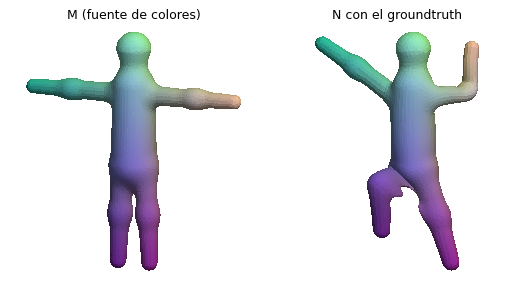

In [35]:
t0 = time.time()
bones = humanoid_bones()
VM, FM = mesh_from_bones(bones, h=0.035)                    # M: pose de reposo
VN_rest, FN = mesh_from_bones(bones, h=0.042)               # N: otra triangulación...
VN = pose_mesh(VN_rest, bones, POSES['humanoide'][3])       # ...y otra pose
T_gt = cKDTree(VM).query(VN_rest)[1]                        # groundtruth N -> M
KMAX = 120
lamM, PhiM, LM, MM = laplace_spectrum(VM, FM, KMAX)
lamN, PhiN, LN, MN = laplace_spectrum(VN, FN, KMAX)
mM, mN = MM.diagonal(), MN.diagonal()
ev = MapEvaluator(VM, FM, VM, T_gt, sym_axis=0)             # simetría izquierda/derecha: x -> -x
print(f'M: {len(VM)} vértices | N: {len(VN)} vértices | {time.time()-t0:.1f} s')
print('λ_2..λ_6 de M:', lamM[1:6].round(3), '\nλ_2..λ_6 de N:', lamN[1:6].round(3))
ev.summary(T_gt, 'groundtruth')

colM = coord_colors(VM)
show_maps(VM, FM, VN, FN, {'N con el groundtruth': T_gt}, colM)

El color de cada punto de $\mathcal M$ viene de su posición; un mapa $T$ "pinta" $\mathcal N$ con
`colM[T]`. Si el mapa es bueno, cada parte de $\mathcal N$ queda del mismo color que en $\mathcal M$.
Ésta será nuestra forma visual de juzgar mapas.

---
# Bloque 1 — Matching isométrico (30 min)

## 1.1 ¿Qué es una buena correspondencia?

En el caso **rígido** (Clase ICP) el mapa es una rotación y una traslación: 6 parámetros.
En el caso **no rígido** no hay una representación compacta: el mapa es una asignación arbitraria
de $n_{\mathcal N}$ puntos a $n_{\mathcal M}$ puntos.

El **modelo isométrico** dice que un buen mapa preserva distancias geodésicas:
$d^{\mathcal M}(T(x),T(y))\approx d^{\mathcal N}(x,y)$. Eso da un criterio para comparar mapas,
la **distorsión**:
$$\mathrm{dis}(T)=\frac{1}{|S|^2}\sum_{x,y\in S}\big|d^{\mathcal N}(x,y)-d^{\mathcal M}(T(x),T(y))\big|,$$
evaluada sobre una muestra $S$ de puntos de $\mathcal N$.

### ✏️ Ejercicio 1 — Distorsión geodésica de un mapa

Implementa `geodesic_distortion(VM, FM, VN, FN, T, S)` que devuelva la distorsión media de
arriba, dividida por $\sqrt{\text{área de }\mathcal M}$ para que no dependa de la escala.
`S` es un arreglo de índices de vértices de $\mathcal N$.

*Pista:* `geodesics_from(V, F, fuentes)` devuelve una matriz `(len(fuentes), n)`; quédate con
las columnas de los mismos puntos para obtener la matriz $|S|\times|S|$.

Los tests comparan cuatro mapas: la groundtruth, su **reflejo** izquierda/derecha, un mapa
**extrínseco** (el vecino más cercano en $\mathbb R^3$ tras alinear centroides, lo que haría un
método rígido) y un mapa **aleatorio**.

In [36]:
# Ejercicio 1 — solución
def geodesic_distortion(VM, FM, VN, FN, T, S):
    DN = geodesics_from(VN, FN, S)[:, S]
    DM = geodesics_from(VM, FM, T[S])[:, T[S]]
    return np.abs(DN - DM).mean() / np.sqrt(face_areas(VM, FM).sum())

In [37]:
# Tests del Ejercicio 1
S = np.random.default_rng(1).choice(len(VN), 150, replace=False)
T_sym = ev.sym[T_gt]                                                  # reflejo izquierda/derecha
T_ext = cKDTree(VM).query(VN - VN.mean(0) + VM.mean(0))[1]            # vecino más cercano en R^3
T_rand = np.random.default_rng(2).integers(0, len(VM), len(VN))
dis = {name: geodesic_distortion(VM, FM, VN, FN, T, S)
       for name, T in [('groundtruth', T_gt), ('reflejo', T_sym), ('extrínseco (R^3)', T_ext), ('aleatorio', T_rand)]}
for name, d in dis.items():
    print(f'{name:18s} distorsión = {d:.4f}')
assert dis['groundtruth'] < 0.03
assert dis['reflejo'] < 2 * dis['groundtruth'], 'el reflejo es (casi) tan isométrico como el mapa correcto'
assert dis['extrínseco (R^3)'] > 2 * dis['groundtruth'] and dis['aleatorio'] > 5 * dis['groundtruth']
print('✅ Ejercicio 1 correcto')

groundtruth        distorsión = 0.0228
reflejo            distorsión = 0.0243
extrínseco (R^3)   distorsión = 0.0842
aleatorio          distorsión = 0.3161
✅ Ejercicio 1 correcto


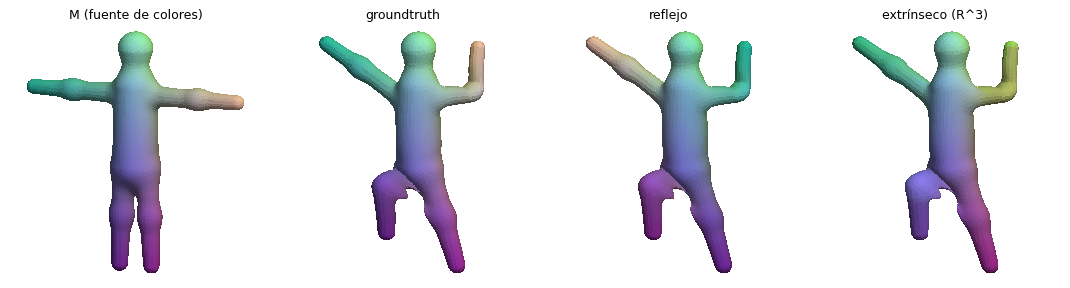

In [38]:
show_maps(VM, FM, VN, FN, {'groundtruth': T_gt, 'reflejo': T_sym, 'extrínseco (R^3)': T_ext}, colM)

Dos lecciones:

* El mapa **extrínseco** (lo que daría un alineamiento rígido) falla en cuanto la pose cambia: el
  brazo levantado de $\mathcal N$ recibe colores del torso de $\mathcal M$.
* El **reflejo** (brazo izquierdo ↔ brazo derecho) tiene una distorsión casi igual a la del mapa
  correcto. Para un criterio puramente intrínseco las dos respuestas son **igual de buenas**: es una
  **simetría intrínseca** de la forma. Vamos a encontrarla de nuevo en todo el tutorial.

## 1.2 Minimizar la distorsión: el problema combinatorio

El enfoque directo es $T_{\text{opt}}=\arg\min_T \mathrm{dis}(T)$. El espacio de
soluciones es discreto, gigantesco y muy no convexo. Para sentirlo, resolvámoslo **por fuerza
bruta** en un caso pequeño: unos pocos puntos característicos (*landmarks*) en cada forma,
detectados de forma independiente con muestreo del punto más lejano (caen en las extremidades).

### ✏️ Ejercicio 2 — Matching de landmarks por fuerza bruta

Implementa `rank_permutations(DM, DN)`: dadas las matrices de distancias geodésicas entre los
$n$ landmarks de cada forma, prueba **todas** las permutaciones `p` (con `itertools.permutations`),
donde el landmark `i` de $\mathcal M$ se asigna al landmark `p[i]` de $\mathcal N$, y devuelve la
lista de pares `(costo, p)` ordenada por costo creciente, con
$$\text{costo}(p)=\tfrac12\sum_{i,j}\big|D^{\mathcal M}_{ij}-D^{\mathcal N}_{p_ip_j}\big| .$$
`p` debe ser un `np.array`.

In [39]:
# Ejercicio 2 — solución
import itertools
def rank_permutations(DM, DN):
    n = len(DM)
    out = []
    for p in itertools.permutations(range(n)):
        p = np.array(p)
        out.append((0.5 * np.abs(DM - DN[np.ix_(p, p)]).sum(), p))
    return sorted(out, key=lambda c: c[0])

In [40]:
# Tests del Ejercicio 2
lmM = farthest_point_sampling(VM, FM, 5)
lmN = farthest_point_sampling(VN, FN, 5)
DM_l = geodesics_from(VM, FM, lmM)[:, lmM]
DN_l = geodesics_from(VN, FN, lmN)[:, lmN]
t0 = time.time(); ranking = rank_permutations(DM_l, DN_l); print(f'{len(ranking)} permutaciones en {time.time()-t0:.3f} s')
assert len(ranking) == 120 and all(ranking[i][0] <= ranking[i + 1][0] for i in range(119))
assert np.isclose(ranking[0][0], min(0.5 * np.abs(DM_l - DN_l[np.ix_(p, p)]).sum() for _, p in ranking))
# Diagnóstico con la groundtruth: ¿a qué distancia (en M) queda cada asignación del landmark correcto?
for c, p in ranking[:4]:
    err = np.linalg.norm(VM[T_gt[lmN[p]]] - VM[lmM], axis=1)
    print(f'costo {c:.3f}  p = {p}  error por landmark: {err.round(2)}')
print('✅ Ejercicio 2 correcto')

120 permutaciones en 0.001 s
costo 0.820  p = [0 1 2 3 4]  error por landmark: [0.05 0.   0.03 0.04 0.04]
costo 0.848  p = [3 2 1 0 4]  error por landmark: [0.49 2.59 2.58 0.46 0.04]
costo 1.653  p = [0 2 1 3 4]  error por landmark: [0.05 2.59 2.58 0.04 0.04]
costo 1.659  p = [3 1 2 0 4]  error por landmark: [0.49 0.   0.03 0.46 0.04]
✅ Ejercicio 2 correcto


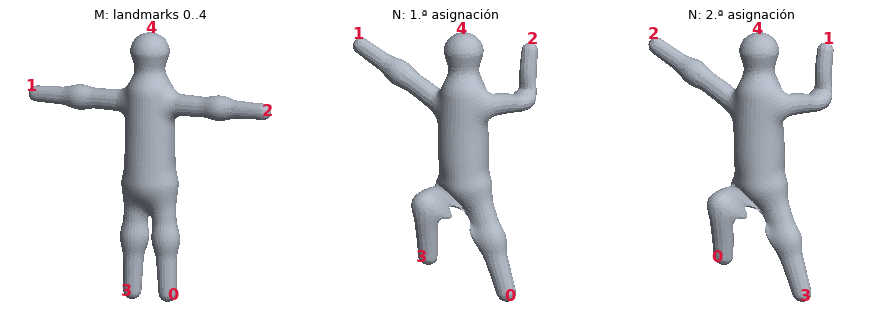

Costos: 1.ª = 0.820, 2.ª = 0.848, 3.ª = 1.653


In [41]:
fig, axs = plt.subplots(1, 3, figsize=(10, 4))
names_lm = [str(i) for i in range(5)]
p_best = ranking[0][1]; p_second = ranking[1][1]
for ax, (V_, F_, lm, ttl) in zip(axs, [(VM, FM, lmM, 'M: landmarks 0..4'),
                                        (VN, FN, lmN[p_best], 'N: 1.ª asignación'),
                                        (VN, FN, lmN[p_second], 'N: 2.ª asignación')]):
    render(ax, V_, F_, view=(10, -25), title=ttl)
    P = (V_ - V_.mean(0)) @ _view_matrix(10, -25).T
    for i, l in enumerate(lm):
        ax.annotate(str(i), P[l, :2], fontsize=13, color='crimson', weight='bold', ha='center')
plt.tight_layout(); plt.show()
print(f'Costos: 1.ª = {ranking[0][0]:.3f}, 2.ª = {ranking[1][0]:.3f}, 3.ª = {ranking[2][0]:.3f}')

* La mejor asignación coincide con la verdad, pero la **segunda** (el reflejo: manos y pies
  izquierdos ↔ derechos) cuesta casi lo mismo. Con otra pose o un poco de ruido el orden se puede
  invertir; lo veremos en el Bloque 6.
* La fuerza bruta escala como $n!$: con 5 puntos son 120 permutaciones; con 10, 3.6 millones;
  con 20, $2.4\times10^{18}$. Para una malla de miles de vértices es imposible. Hay
  relajaciones (asignación cuadrática, GMDS de Bronstein et al. 2006, *Blended Intrinsic Maps*),
  pero el problema sigue siendo no convexo.

Los **mapas funcionales** cambian la pregunta: en vez de buscar una asignación de puntos, buscan
una **matriz pequeña** que transforma funciones. Ahí las restricciones se vuelven **lineales**.
Estos 5 landmarks no se pierden: los reutilizaremos como restricciones en el Bloque 4.

---
# Bloque 2 — El mapa funcional (40 min)

## 2.1 Un mapa entre puntos induce un mapa entre funciones

Un mapa $T:\mathcal N\to\mathcal M$ permite "traer" cualquier función $f:\mathcal M\to\mathbb R$
a $\mathcal N$ por composición:
$$T_F(f)=g=f\circ T,\qquad g(y)=f(T(y)).$$
$T_F$ va **en sentido contrario** a $T$: de funciones en $\mathcal M$ a funciones en $\mathcal N$.
Y es **lineal**, aunque $T$ sea arbitrariamente complicado:
$T_F(\alpha f_1+\beta f_2)=\alpha T_F(f_1)+\beta T_F(f_2)$.

En la malla, una función es un vector y $T_F$ es una matriz
$\boldsymbol\Pi\in\{0,1\}^{n_{\mathcal N}\times n_{\mathcal M}}$ con $\Pi_{y,T(y)}=1$: **un 1 por
fila**, y $\mathbf g=\boldsymbol\Pi\mathbf f$  allí se escribe con la transpuesta, es
la misma matriz con la convención de índices al revés).

### ✏️ Ejercicio 3 — La matriz de un mapa punto a punto

Implementa `pointwise_to_matrix(T, nM)` que devuelva $\boldsymbol\Pi$ como matriz rala
(`sp.csr_matrix`) de tamaño $n_{\mathcal N}\times n_{\mathcal M}$, con `nN = len(T)`.

In [42]:
# Ejercicio 3 — solución
def pointwise_to_matrix(T, nM):
    nN = len(T)
    return sp.csr_matrix((np.ones(nN), (np.arange(nN), T)), shape=(nN, nM))

In [43]:
# Tests del Ejercicio 3
Pi_gt = pointwise_to_matrix(T_gt, len(VM))
assert Pi_gt.shape == (len(VN), len(VM)) and sp.issparse(Pi_gt)
assert np.allclose(Pi_gt @ np.ones(len(VM)), 1), 'un 1 por fila'
f1, f2 = VM[:, 1], np.sin(4 * VM[:, 0])
assert np.allclose(Pi_gt @ f1, f1[T_gt]), 'Π f = f∘T'
assert np.allclose(Pi_gt @ (2 * f1 - 3 * f2), 2 * (Pi_gt @ f1) - 3 * (Pi_gt @ f2)), 'linealidad'
print('✅ Ejercicio 3 correcto')

✅ Ejercicio 3 correcto


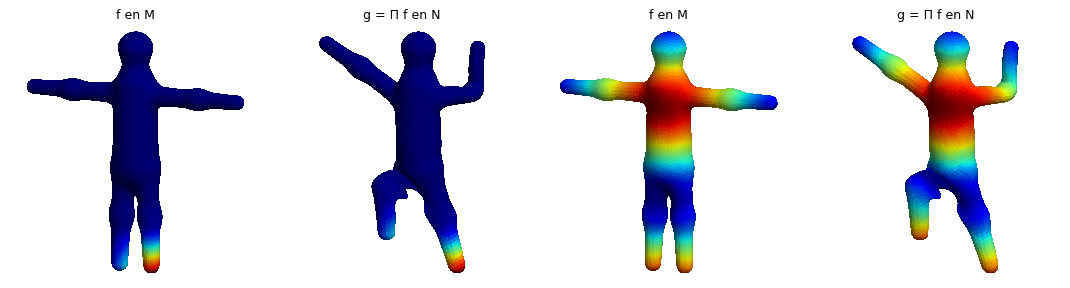

In [44]:
# Transferencia exacta de funciones con la groundtruth
f_leg = np.exp(-np.linalg.norm(VM - VM[np.argmin(VM[:, 1] - 0.3 * VM[:, 0])], axis=1) ** 2 / 0.1)  # "calor" en el pie izq.
f_wave = np.sin(3 * VM[:, 1]) * np.cos(2 * VM[:, 0])
fig, axs = plt.subplots(1, 4, figsize=(12, 4))
render(axs[0], VM, FM, f_leg, cmap='jet', view=(10, -25), title='f en M')
render(axs[1], VN, FN, Pi_gt @ f_leg, cmap='jet', view=(10, -25), title='g = Π f en N')
render(axs[2], VM, FM, f_wave, cmap='jet', view=(10, -25), title='f en M')
render(axs[3], VN, FN, Pi_gt @ f_wave, cmap='jet', view=(10, -25), title='g = Π f en N')
plt.tight_layout(); plt.show()

$\boldsymbol\Pi$ es **exacta** pero enorme ($n_{\mathcal N}\times n_{\mathcal M}$) y no tiene
estructura útil para optimizar. La idea clave: expresar las funciones en una
**base** pequeña y "suave".

## 2.2 El mapa funcional en la base de Laplace–Beltrami

Escribimos $f=\sum_i a_i\phi_i^{\mathcal M}$ y $g=T_F(f)=\sum_j b_j\phi_j^{\mathcal N}$ con las
eigenfunciones de cada forma  ordenadas por frecuencia, dan una noción de escala).
Como $T_F$ es lineal, existe una matriz $\mathbf C$ con $\mathbf b=\mathbf C\mathbf a$:
$$C_{ji}=\langle T_F(\phi_i^{\mathcal M}),\,\phi_j^{\mathcal N}\rangle_{\mathcal N}
\quad\Longrightarrow\quad
\mathbf C=\boldsymbol\Phi_{\mathcal N}^\top\mathbf M_{\mathcal N}\,\boldsymbol\Pi\,\boldsymbol\Phi_{\mathcal M}\ \in\mathbb R^{k_{\mathcal N}\times k_{\mathcal M}} .$$
Con $k=30$ la matriz tiene 900 números, contra $n_{\mathcal N}\cdot n_{\mathcal M}\approx 2\cdot10^7$
de $\boldsymbol\Pi$. Truncar la base es aproximar: sólo se transfieren bien las funciones
suaves (las que se describen con pocas eigenfunciones).

### ✏️ Ejercicio 4 — Mapa funcional a partir de un mapa punto a punto

Implementa `fmap_from_pointwise(T, PhiM, PhiN, mN, k)` que devuelva la matriz
$\mathbf C$ de tamaño $k\times k$ usando las primeras `k` eigenfunciones de cada forma. `mN` es la
diagonal de $\mathbf M_{\mathcal N}$ (un vector). **No** construyas $\boldsymbol\Pi$:
$\boldsymbol\Pi\boldsymbol\Phi_{\mathcal M}$ es simplemente `PhiM[T]`.

In [45]:
# Ejercicio 4 — solución
def fmap_from_pointwise(T, PhiM, PhiN, mN, k):
    return PhiN[:, :k].T @ (mN[:, None] * PhiM[T, :k])

In [46]:
# Tests del Ejercicio 4
k = 30
C_gt = fmap_from_pointwise(T_gt, PhiM, PhiN, mN, k)
assert C_gt.shape == (k, k)
assert np.allclose(C_gt, PhiN[:, :k].T @ MN @ (Pi_gt @ PhiM[:, :k])), 'debe coincidir con Φ_N^T M_N Π Φ_M'
C_sym = fmap_from_pointwise(T_sym, PhiM, PhiN, mN, k)
C_rand = fmap_from_pointwise(T_rand, PhiM, PhiN, mN, k)
orth = lambda C: np.linalg.norm(C.T @ C - np.eye(len(C))) / np.sqrt(len(C))
diag = lambda C: (np.diag(C)[1:] ** 2).sum() / (C[1:, 1:] ** 2).sum()   # sin C_11: φ1 constante va siempre a ±constante
for name, C in [('verdad', C_gt), ('reflejo', C_sym), ('aleatorio', C_rand)]:
    print(f'{name:10s} C_11 = {C[0, 0]:+.3f} | ‖CᵀC − I‖/√k = {orth(C):.3f} | energía en la diagonal (sin C_11) = {diag(C):.2f}')
assert orth(C_gt) < 0.3 and diag(C_gt) > 0.5
assert orth(C_rand) > 0.5 and diag(C_rand) < 0.2
print('✅ Ejercicio 4 correcto')

verdad     C_11 = -0.998 | ‖CᵀC − I‖/√k = 0.220 | energía en la diagonal (sin C_11) = 0.67
reflejo    C_11 = -0.998 | ‖CᵀC − I‖/√k = 0.215 | energía en la diagonal (sin C_11) = 0.67
aleatorio  C_11 = -0.998 | ‖CᵀC − I‖/√k = 0.975 | energía en la diagonal (sin C_11) = 0.03
✅ Ejercicio 4 correcto


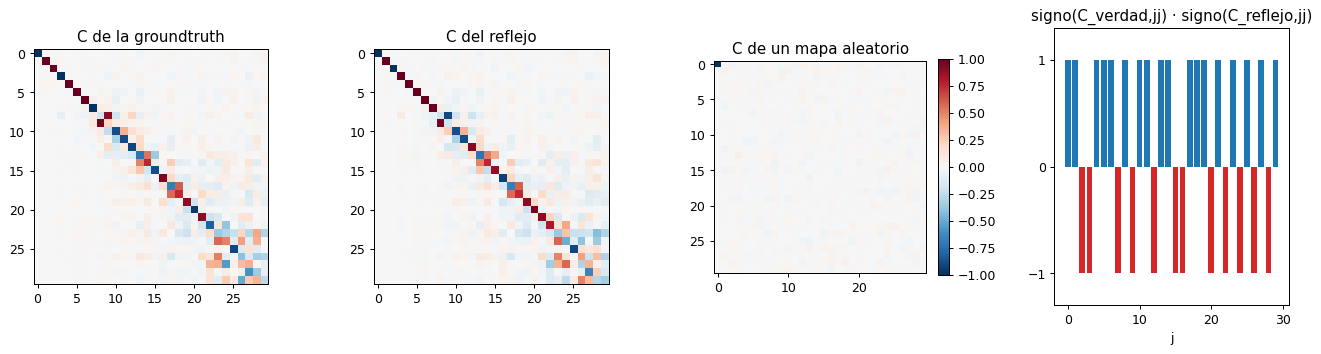

In [47]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4), gridspec_kw={'wspace': 0.45})
for ax, (C, ttl) in zip(axs, [(C_gt, 'C de la groundtruth'), (C_sym, 'C del reflejo'), (C_rand, 'C de un mapa aleatorio')]):
    im = ax.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_title(ttl)
fig.colorbar(im, ax=axs[2], fraction=0.046)
s = np.sign(np.diag(C_gt)) * np.sign(np.diag(C_sym))
axs[3].bar(range(k), s, color=['tab:blue' if v > 0 else 'tab:red' for v in s])
axs[3].set(title='signo(C_verdad,jj) · signo(C_reflejo,jj)', xlabel='j', ylim=(-1.3, 1.3), yticks=[-1, 0, 1])
plt.show()

* La $\mathbf C$ de un buen mapa es **casi diagonal**: las eigenfunciones de una forma
  van a las eigenfunciones de la otra. Lo que se aleja de la diagonal son bloques de eigenvalores
  casi repetidos y las frecuencias altas.
* La $\mathbf C$ del **reflejo** tiene el mismo patrón, pero algunas entradas diagonales con el
  **signo opuesto**: las eigenfunciones **antisimétricas** (por ejemplo, la que separa el brazo
  izquierdo del derecho) cambian de signo bajo la reflexión. En el lenguaje funcional, la simetría
  es simplemente $\mathbf C_{\text{reflejo}}\approx\mathbf C\,\mathbf S$ con $\mathbf S$ diagonal de $\pm1$.
* La $\mathbf C$ de un mapa aleatorio no tiene estructura: casi todo $\phi_i$ se manda a ruido de
  alta frecuencia, que la base truncada no puede representar. Sólo sobrevive $C_{11}=\pm1$:
  **cualquier** mapa lleva la función constante a la constante.

### Dos propiedades que usaremos para estimar $\mathbf C$

1. **Isometría ⇒ $\mathbf C$ conmuta con el Laplaciano**: $\boldsymbol\Lambda_{\mathcal N}\mathbf C=\mathbf C\boldsymbol\Lambda_{\mathcal M}$,
   es decir $(\lambda^{\mathcal N}_j-\lambda^{\mathcal M}_i)\,C_{ji}=0$. Las entradas sólo pueden ser
   grandes donde los valores propios coinciden: de ahí la forma diagonal.
2. **Preservar área ⇒ $\mathbf C$ ortogonal**: $\mathbf C^\top\mathbf C=\mathbf I$ (lo usaremos en
   el ICP espectral).

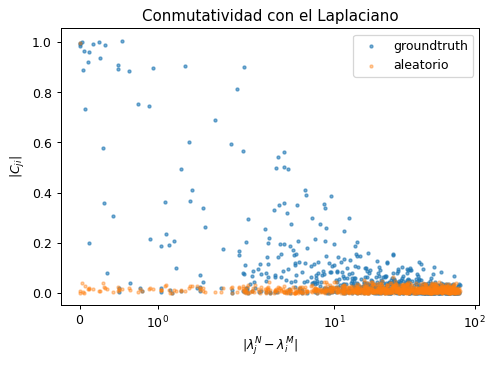

verdad     ‖ΛN C − C ΛM‖ / ‖C‖ = 5.85
reflejo    ‖ΛN C − C ΛM‖ / ‖C‖ = 5.86
aleatorio  ‖ΛN C − C ΛM‖ / ‖C‖ = 15.91


In [48]:
dl = np.abs(lamN[:k, None] - lamM[None, :k])
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(dl.ravel(), np.abs(C_gt).ravel(), s=6, alpha=.6, label='groundtruth')
ax.scatter(dl.ravel(), np.abs(C_rand).ravel(), s=6, alpha=.4, label='aleatorio')
ax.set(xscale='symlog', xlabel=r'$|\lambda^N_j-\lambda^M_i|$', ylabel=r'$|C_{ji}|$', title='Conmutatividad con el Laplaciano'); ax.legend()
plt.show()
for name, C in [('verdad', C_gt), ('reflejo', C_sym), ('aleatorio', C_rand)]:
    print(f'{name:10s} ‖ΛN C − C ΛM‖ / ‖C‖ = {np.linalg.norm(lamN[:k, None] * C - C * lamM[None, :k]) / np.linalg.norm(C):.2f}')

## 2.3 Transferir funciones con $\mathbf C$

Con $\mathbf C$ transferimos cualquier función en tres pasos: coeficientes en
$\mathcal M$, multiplicar por $\mathbf C$, volver a $\mathcal N$:
$$T_F(f)\approx\boldsymbol\Phi_{\mathcal N}\,\mathbf C\,\boldsymbol\Phi_{\mathcal M}^\top\mathbf M_{\mathcal M}\,\mathbf f .$$

### ✏️ Ejercicio 5 — Transferencia de funciones con el mapa funcional

Implementa `transfer_function(f, C, PhiM, PhiN, mM)`. Usa tantas eigenfunciones como indique el
tamaño de `C` (puede ser rectangular: $k_{\mathcal N}\times k_{\mathcal M}$). `f` puede ser un
vector o una matriz `(nM, d)`.

In [49]:
# Ejercicio 5 — solución
def transfer_function(f, C, PhiM, PhiN, mM):
    kN, kM = C.shape
    a = PhiM[:, :kM].T @ (mM * f.T).T if f.ndim == 2 else PhiM[:, :kM].T @ (mM * f)
    return PhiN[:, :kN] @ (C @ a)

In [50]:
# Tests del Ejercicio 5
g = transfer_function(PhiM[:, 3], C_gt, PhiM, PhiN, mM)
assert np.allclose(g, PhiN[:, :k] @ C_gt[:, 3]), 'φ_4 de M se transfiere como la columna 4 de C'
G2 = transfer_function(np.stack([f_wave, f_leg], 1), C_gt, PhiM, PhiN, mM)
assert G2.shape == (len(VN), 2)
rel = lambda a, b: np.sqrt(((a - b) ** 2) @ mN / (b ** 2 @ mN))
errs = {kk: rel(transfer_function(f_wave, fmap_from_pointwise(T_gt, PhiM, PhiN, mN, kk), PhiM, PhiN, mM), Pi_gt @ f_wave)
        for kk in [10, 30, 60, 100]}
print('error relativo al transferir f_wave con C de tamaño k:', {kk: round(e, 3) for kk, e in errs.items()})
assert errs[100] < errs[10] and errs[100] < 0.15
print('✅ Ejercicio 5 correcto')

error relativo al transferir f_wave con C de tamaño k: {10: np.float64(0.102), 30: np.float64(0.072), 60: np.float64(0.049), 100: np.float64(0.038)}
✅ Ejercicio 5 correcto


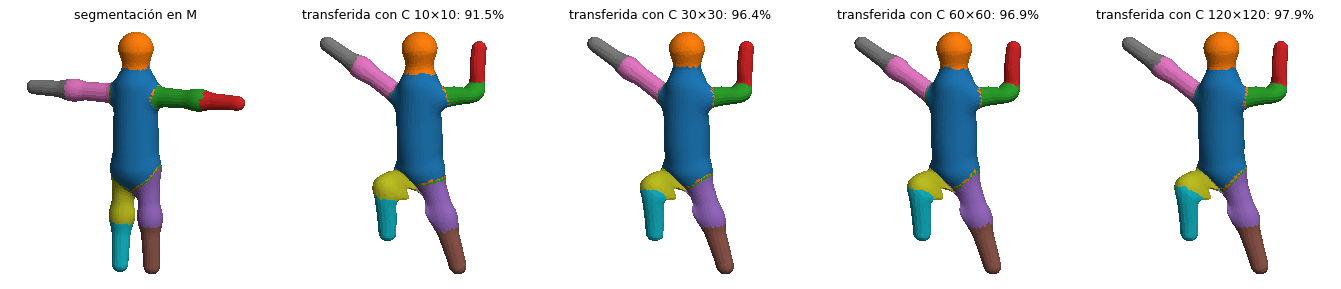

In [51]:
# Transferir una segmentación: las partes del cuerpo como funciones indicadoras
names_parts = [b['name'] for b in bones]
def seg_dist(P, a, b):
    ab = b - a; t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)
labels_M = np.argmin(np.stack([seg_dist(VM, b['a'], b['b']) - b['r'] for b in bones], 1), 1)
labels_N_gt = labels_M[T_gt]
onehot = np.eye(len(bones))[labels_M]
fig, axs = plt.subplots(1, 5, figsize=(15, 4))
render(axs[0], VM, FM, labels_M, cmap='tab10', view=(10, -25), title='segmentación en M')
for ax, kk in zip(axs[1:], [10, 30, 60, 120]):
    Ck = fmap_from_pointwise(T_gt, PhiM, PhiN, mN, kk)
    lab = np.argmax(transfer_function(onehot, Ck, PhiM, PhiN, mM), 1)
    render(ax, VN, FN, lab, cmap='tab10', view=(10, -25), title=f'transferida con C {kk}×{kk}: {np.mean(lab == labels_N_gt):.1%}')
plt.tight_layout(); plt.show()

Las funciones indicadoras son discontinuas, así que con pocas eigenfunciones se transfieren con
bordes difusos (el fenómeno de Gibbs de la Clase 13), pero el `argmax` recupera las partes con
alta exactitud. Toda la información del mapa cabe en una matriz pequeña.

**Hasta ahora hicimos trampa**: construimos $\mathbf C$ a partir del groundtruth. Quedan dos
preguntas: ¿cómo volver de $\mathbf C$ a un mapa punto a punto?, y ¿cómo estimar
$\mathbf C$ sin conocer el mapa?

---
# Bloque 3 — De $\mathbf C$ a un mapa punto a punto (15 min)

Si $\mathbf C$ viene de un mapa $T$, entonces $\boldsymbol\Pi\boldsymbol\Phi_{\mathcal M}\approx\boldsymbol\Phi_{\mathcal N}\mathbf C$
(transferir cada eigenfunción de $\mathcal M$). Leído **fila por fila**:
$$\underbrace{\boldsymbol\Phi_{\mathcal M}[T(y),:]}_{\text{fila de }T(y)\text{ en }\mathcal M}\;\approx\;\underbrace{(\boldsymbol\Phi_{\mathcal N}\mathbf C)[y,:]}_{\text{fila de }y\text{, llevada a la base de }\mathcal M}$$
Cada vértice es un punto en $\mathbb R^k$ (su *embedding espectral*, como el GPS de la Clase 13).
$\mathbf C$ alinea los dos embeddings, y el mapa se recupera con **vecino más cercano** en
$\mathbb R^k$:
$$T(y)=\arg\min_x\big\|\boldsymbol\Phi_{\mathcal M}[x,:]-(\boldsymbol\Phi_{\mathcal N}\mathbf C)[y,:]\big\| .$$

### ✏️ Ejercicio 6 — Conversión de mapa funcional a punto a punto

Implementa `pointwise_from_fmap(C, PhiM, PhiN)` para una $\mathbf C$ de tamaño $k\times k$, usando
`nn_search(X, Q)` (vecino más cercano de cada fila de `Q` entre las filas de `X`).

In [52]:
# Ejercicio 6 — solución
def pointwise_from_fmap(C, PhiM, PhiN):
    k = C.shape[0]
    return nn_search(PhiM[:, :k], PhiN[:, :k] @ C)

In [53]:
# Tests del Ejercicio 6
T_rec = pointwise_from_fmap(C_gt, PhiM, PhiN)
assert T_rec.shape == (len(VN),) and T_rec.max() < len(VM)
med = ev.summary(T_rec, 'recuperado de C verdad (k=30)')
assert med < 0.03
print('✅ Ejercicio 6 correcto')

recuperado de C verdad (k=30)    error mediano 0.015 | medio 0.024 | mediano módulo simetría 0.015
✅ Ejercicio 6 correcto


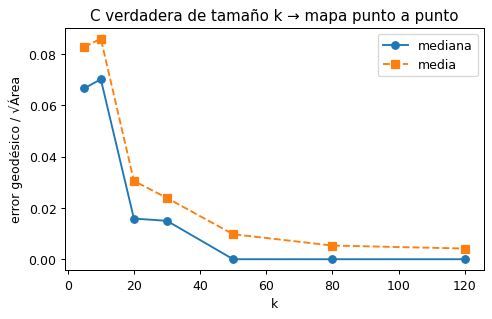

error mediano por k: {5: np.float64(0.0666), 10: np.float64(0.0702), 20: np.float64(0.0159), 30: np.float64(0.015), 50: np.float64(0.0), 80: np.float64(0.0), 120: np.float64(0.0)}
error medio por k:   {5: np.float64(0.0828), 10: np.float64(0.086), 20: np.float64(0.0305), 30: np.float64(0.0239), 50: np.float64(0.0098), 80: np.float64(0.0053), 120: np.float64(0.0042)}


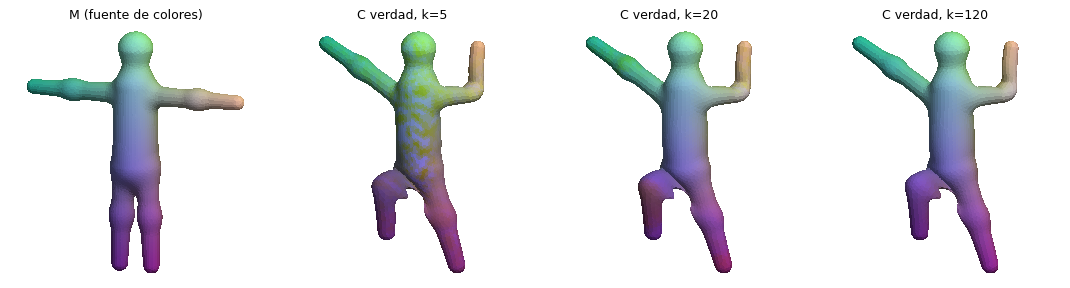

In [54]:
ks = [5, 10, 20, 30, 50, 80, 120]
meds, means = [], []
for kk in ks:
    e = ev.errors(pointwise_from_fmap(fmap_from_pointwise(T_gt, PhiM, PhiN, mN, kk), PhiM, PhiN))
    meds.append(np.median(e)); means.append(e.mean())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ks, meds, 'o-', label='mediana'); ax.plot(ks, means, 's--', label='media')
ax.set(xlabel='k', ylabel='error geodésico / √Área', title='C verdadera de tamaño k → mapa punto a punto'); ax.legend()
plt.show()
print('error mediano por k:', dict(zip(ks, np.round(meds, 4))))
print('error medio por k:  ', dict(zip(ks, np.round(means, 4))))
show_maps(VM, FM, VN, FN, {f'C verdad, k={kk}': pointwise_from_fmap(fmap_from_pointwise(T_gt, PhiM, PhiN, mN, kk), PhiM, PhiN)
                           for kk in [5, 20, 120]}, colM)

Con $\mathbf C$ perfecta, la calidad del mapa sólo depende de $k$: con pocas eigenfunciones el
embedding no distingue puntos cercanos (el mapa es "en bloques"); desde $k\approx50$ la mayoría
de los vértices cae **exactamente** en el vértice correcto (mediana 0) y el error medio se acerca
a la resolución de la malla. Esta curva es la **cota** de lo que podemos lograr con cada $k$.
Usaremos esta conversión en todo lo que sigue.

---
# Bloque 4 — Estimar $\mathbf C$ sin conocer el mapa (40 min)

Ovsjanikov, Ben-Chen, Solomon, Butscher y Guibas (SIGGRAPH 2012). La observación central: casi
todo lo que sabemos de un buen mapa se escribe como una **ecuación lineal en $\mathbf C$**.

**1. Preservación de descriptores.** Si $f:\mathcal M\to\mathbb R$ y $g:\mathcal N\to\mathbb R$ son
"la misma" función (por ejemplo, la WKS a una misma energía, que es intrínseca), entonces
$T_F(f)\approx g$, o sea $\mathbf C\mathbf a\approx\mathbf b$ con $\mathbf a,\mathbf b$ sus
coeficientes. Con $q$ pares de descriptores apilados como columnas:
$$\mathbf C\mathbf A\approx\mathbf B,\qquad \mathbf A=\boldsymbol\Phi_{\mathcal M}^\top\mathbf M_{\mathcal M}\mathbf F_{\mathcal M}\in\mathbb R^{k\times q},\quad \mathbf B=\boldsymbol\Phi_{\mathcal N}^\top\mathbf M_{\mathcal N}\mathbf F_{\mathcal N}.$$

**2. Landmarks.** Si sabemos que $\ell_i\in\mathcal M$ corresponde a $\ell'_i\in\mathcal N$, las
funciones "concentradas" alrededor de ellos (por ejemplo el kernel de calor $h_t(\ell_i,\cdot)$)
también deben corresponder: son descriptores **no simétricos**.

**3. Conmutatividad con el Laplaciano** (isometrías): $\boldsymbol\Lambda_{\mathcal N}\mathbf C\approx\mathbf C\boldsymbol\Lambda_{\mathcal M}$.

Todo junto:
$$\mathbf C^\star=\arg\min_{\mathbf C}\ \|\mathbf C\mathbf A-\mathbf B\|_F^2+\mu\sum_{j,i}\big(\lambda^{\mathcal N}_j-\lambda^{\mathcal M}_i\big)^2C_{ji}^2 .$$

Es un problema de **mínimos cuadrados**, y además se **desacopla por filas**: la fila $\mathbf c_j$
de $\mathbf C$ sólo aparece en su propio término. Derivando,
$$\big(\mathbf A\mathbf A^\top+\mu\,\mathbf D_j\big)\,\mathbf c_j^\top=\mathbf A\,\mathbf b_j^\top,\qquad
\mathbf D_j=\operatorname{diag}\big((\lambda^{\mathcal N}_j-\lambda^{\mathcal M}_i)^2\big)_{i=1..k},$$
donde $\mathbf b_j$ es la fila $j$ de $\mathbf B$: son $k$ sistemas lineales de $k\times k$.

### ✏️ Ejercicio 7 — Estimación del mapa funcional por mínimos cuadrados

Implementa `solve_fmap(A, B, lamM, lamN, mu)` resolviendo los $k$ sistemas de arriba
(`A`, `B` de tamaño $k\times q$; `lamM`, `lamN` de largo $k$). Devuelve $\mathbf C$ de $k\times k$.

In [55]:
# Ejercicio 7 — solución
def solve_fmap(A, B, lamM, lamN, mu):
    k = A.shape[0]
    C = np.zeros((k, k))
    AAt = A @ A.T
    for j in range(k):
        Dj = np.diag((lamN[j] - lamM) ** 2)
        C[j] = np.linalg.solve(AAt + mu * Dj, A @ B[j])
    return C

In [56]:
# Tests del Ejercicio 7
rng = np.random.default_rng(0)
Cstar = rng.normal(size=(10, 10)); A_t = rng.normal(size=(10, 40))
assert np.allclose(solve_fmap(A_t, Cstar @ A_t, np.arange(10.), np.arange(10.), 0.0), Cstar), 'sin ruido y μ=0 recupera C'
lm_t, ln_t = np.sort(rng.uniform(0, 5, 10)), np.sort(rng.uniform(0, 5, 10))
B_t = Cstar @ A_t + 0.3 * rng.normal(size=(10, 40))
C_t = solve_fmap(A_t, B_t, lm_t, ln_t, 0.5)
E = lambda C: np.linalg.norm(C @ A_t - B_t) ** 2 + 0.5 * (((ln_t[:, None] - lm_t[None]) ** 2) * C ** 2).sum()
assert all(E(C_t) <= E(C_t + 1e-3 * rng.normal(size=C_t.shape)) for _ in range(20)), 'debe ser el mínimo'
print('✅ Ejercicio 7 correcto')

✅ Ejercicio 7 correcto


### Los descriptores

Usamos la WKS de la Clase 13 (50 energías) y, opcionalmente, kernels de calor alrededor de los
**5 landmarks** que emparejamos por fuerza bruta en el Ejercicio 2 (con la mejor asignación).
Cada columna se normaliza para que todas pesen parecido.

WKS, μ=0                         error mediano 0.393 | medio 0.419 | mediano módulo simetría 0.378
WKS, μ=1e-2                      error mediano 0.144 | medio 0.188 | mediano módulo simetría 0.143
WKS + landmarks, μ=1e-2          error mediano 0.063 | medio 0.070 | mediano módulo simetría 0.063
WKS + landmarks (2.ª asig.)      error mediano 0.252 | medio 0.363 | mediano módulo simetría 0.063


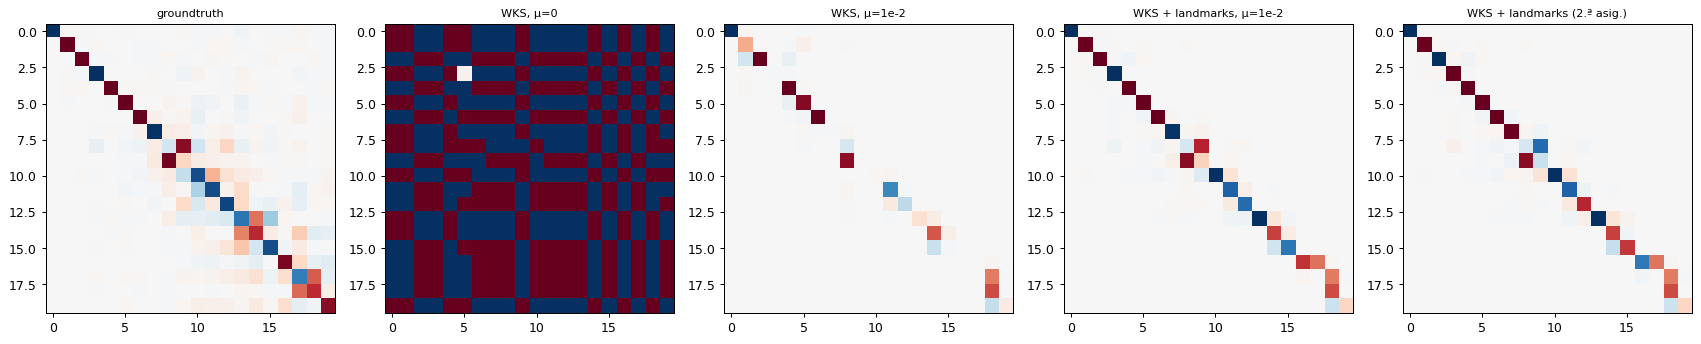

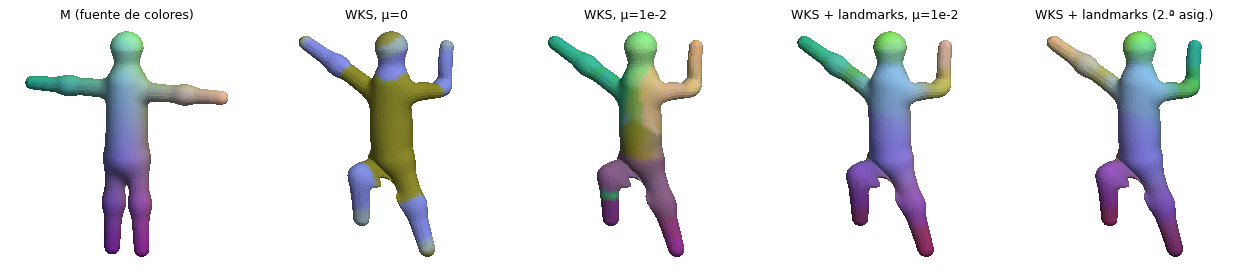

In [57]:
def build_descriptors(lam, Phi, m, landmarks=None, E=50, ts=(0.05, 0.2)):
    D = [wks(lam, Phi, E)]
    if landmarks is not None:
        for t in ts:
            D.append(np.stack([heat_kernel(lam, Phi, l, t) for l in landmarks], 1))
    D = np.hstack(D)
    return D / np.sqrt(m @ D ** 2)                     # norma L2(M) = 1 por columna

def coeffs(F, Phi, m, k):
    return Phi[:, :k].T @ (m[:, None] * F)

k0 = 20
lmN_best, lmN_second = lmN[ranking[0][1]], lmN[ranking[1][1]]
configs = {
    'WKS, μ=0':                    (None, None, 0.0),
    'WKS, μ=1e-2':                 (None, None, 1e-2),
    'WKS + landmarks, μ=1e-2':     (lmM, lmN_best, 1e-2),
    'WKS + landmarks (2.ª asig.)': (lmM, lmN_second, 1e-2),
}
C_est, T_est = {}, {}
for name, (lM_, lN_, mu) in configs.items():
    A = coeffs(build_descriptors(lamM, PhiM, mM, lM_), PhiM, mM, k0)
    B = coeffs(build_descriptors(lamN, PhiN, mN, lN_), PhiN, mN, k0)
    C_est[name] = solve_fmap(A, B, lamM[:k0], lamN[:k0], mu)
    T_est[name] = pointwise_from_fmap(C_est[name], PhiM, PhiN)
    ev.summary(T_est[name], name)
C_gt20 = fmap_from_pointwise(T_gt, PhiM, PhiN, mN, k0)
fig, axs = plt.subplots(1, 5, figsize=(19, 3.8))
for ax, (name, C) in zip(axs, [('groundtruth', C_gt20)] + list(C_est.items())):
    ax.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1); ax.set_title(name, fontsize=9)
plt.tight_layout(); plt.show()
show_maps(VM, FM, VN, FN, T_est, colM, size=2.8)

Qué pasó:

* **Sólo WKS, sin regularizar**: la WKS depende de $\phi_k^2$, así que es ciega al **signo** de
  las eigenfunciones y a la simetría izquierda/derecha. El sistema está mal condicionado y
  $\mathbf C$ sale con entradas enormes y sin estructura.
* **+ conmutatividad**: $\mathbf C$ se vuelve casi diagonal, pero los signos siguen sin estar
  determinados: el mapa mezcla trozos correctos con trozos reflejados.
* **+ landmarks**: 5 correspondencias puntuales bastan para fijar los signos. El error cae a
  unos pocos por ciento de $\sqrt{\text{área}}$.
* **Landmarks con la 2.ª asignación** (la reflejada del Ejercicio 2): obtenemos un mapa igual de
  limpio, pero **reflejado**. Error grande contra la groundtruth, pero pequeño **módulo
  simetría**. Para el método las dos respuestas son igual de válidas.

> **Para discutir:** ¿por qué la WKS sola no puede fijar el signo de $\phi_j$, y en cambio un kernel
> de calor $h_t(\ell,\cdot)$ sí?

---
# Bloque 5 — Refinamiento: ICP espectral y ZoomOut (30 min)

La $\mathbf C$ estimada es buena "a grandes rasgos", pero el mapa punto a punto todavía tiene
errores. Dos ideas para mejorarlo alternan entre las dos representaciones.

## 5.1 ICP espectral (Ovsjanikov et al., 2012)

Es el ICP de la Clase 6, pero en el espacio espectral $\mathbb R^k$: los "puntos" son las filas
de $\boldsymbol\Phi_{\mathcal M}$ y $\boldsymbol\Phi_{\mathcal N}$, y la "rotación" es $\mathbf C$.

1. **Correspondencias**: $T\leftarrow$ vecino más cercano de $\boldsymbol\Phi_{\mathcal N}\mathbf C$ en $\boldsymbol\Phi_{\mathcal M}$ (Ejercicio 6).
2. **Ajuste**: $\mathbf C\leftarrow\boldsymbol\Phi_{\mathcal N}^\top\mathbf M_{\mathcal N}\boldsymbol\Pi_T\boldsymbol\Phi_{\mathcal M}$ (Ejercicio 4),
   **proyectada a la matriz ortogonal más cercana** (las isometrías preservan el área): si
   $\mathbf C=\mathbf U\boldsymbol\Sigma\mathbf V^\top$, tomamos $\mathbf C\leftarrow\mathbf U\mathbf V^\top$
   (el mismo truco de Procrustes/Kabsch que en el ICP rígido).

### ✏️ Ejercicio 8 — ICP espectral

Implementa `spectral_icp(C, PhiM, PhiN, mN, iters=10)` que devuelva la $\mathbf C$ final
(ortogonal, del mismo tamaño que la inicial) y el mapa punto a punto que induce.

In [58]:
# Ejercicio 8 — solución
def spectral_icp(C, PhiM, PhiN, mN, iters=10):
    k = C.shape[0]
    for _ in range(iters):
        T = pointwise_from_fmap(C, PhiM, PhiN)
        C = fmap_from_pointwise(T, PhiM, PhiN, mN, k)
        U, _, Vt = np.linalg.svd(C)
        C = U @ Vt
    return C, pointwise_from_fmap(C, PhiM, PhiN)

In [59]:
# Tests del Ejercicio 8
C0 = C_est['WKS + landmarks, μ=1e-2']
t0 = time.time(); C_icp, T_icp = spectral_icp(C0, PhiM, PhiN, mN); print(f'{time.time()-t0:.1f} s')
assert C_icp.shape == C0.shape and np.allclose(C_icp.T @ C_icp, np.eye(len(C0)), atol=1e-8), 'C debe ser ortogonal'
e0, e1 = ev.summary(T_est['WKS + landmarks, μ=1e-2'], 'inicial (k=20)'), ev.summary(T_icp, 'ICP espectral (k=20)')
assert e1 < e0
print('✅ Ejercicio 8 correcto')

1.9 s
inicial (k=20)                   error mediano 0.063 | medio 0.070 | mediano módulo simetría 0.063
ICP espectral (k=20)             error mediano 0.028 | medio 0.039 | mediano módulo simetría 0.028
✅ Ejercicio 8 correcto


## 5.2 ZoomOut (Melzi, Ren, Rodolà, Sharma, Wonka y Ovsjanikov, 2019)

El ICP mejora el mapa, pero queda limitado por $k=20$: la cota del Bloque 3 muestra que con 20
eigenfunciones no se pueden distinguir puntos cercanos. **ZoomOut** usa el mismo par de pasos,
pero **agranda la base de a poco**: en cada iteración convierte $\mathbf C_{k\times k}$ en un mapa
punto a punto y con él calcula $\mathbf C_{(k+1)\times(k+1)}$. Sin proyección ortogonal ni
ningún otro ingrediente.

¿Por qué funciona? Un mapa bueno en las frecuencias bajas da información **correcta** sobre la
frecuencia siguiente; aumentar $k$ de a uno nunca le pide al método adivinar demasiado.

### ✏️ Ejercicio 9 — ZoomOut

Implementa `zoomout(C, PhiM, PhiN, mN, kmax, step=1)`: mientras $k<k_{\max}$, calcula el mapa
punto a punto con la $\mathbf C$ actual, aumenta $k$ en `step` (sin pasarte de `kmax`) y calcula la
nueva $\mathbf C$ de $k\times k$. Devuelve la $\mathbf C$ final y su mapa punto a punto.

In [60]:
# Ejercicio 9 — solución
def zoomout(C, PhiM, PhiN, mN, kmax, step=1):
    k = C.shape[0]
    while k < kmax:
        T = pointwise_from_fmap(C, PhiM, PhiN)
        k = min(k + step, kmax)
        C = fmap_from_pointwise(T, PhiM, PhiN, mN, k)
    return C, pointwise_from_fmap(C, PhiM, PhiN)

In [61]:
# Tests del Ejercicio 9
t0 = time.time(); C_zo, T_zo = zoomout(C0, PhiM, PhiN, mN, KMAX); print(f'ZoomOut 20 → {KMAX}: {time.time()-t0:.1f} s')
assert C_zo.shape == (KMAX, KMAX)
e2 = ev.summary(T_zo, f'ZoomOut (20 → {KMAX})')
assert e2 < 0.03
Cs, _ = zoomout(np.eye(3), PhiM, PhiN, mN, 10, step=4)
assert Cs.shape == (10, 10), 'el último paso no debe pasarse de kmax'
print('✅ Ejercicio 9 correcto')

ZoomOut 20 → 120: 23.4 s
ZoomOut (20 → 120)               error mediano 0.018 | medio 0.041 | mediano módulo simetría 0.018
✅ Ejercicio 9 correcto


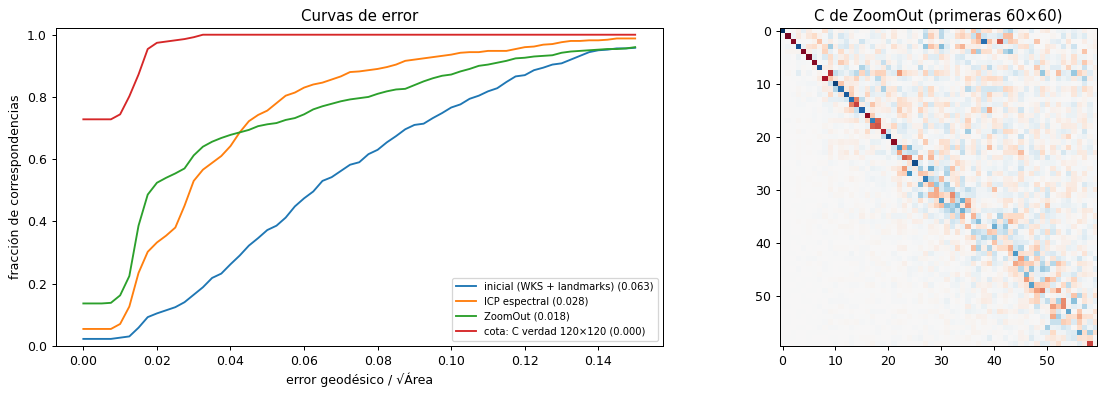

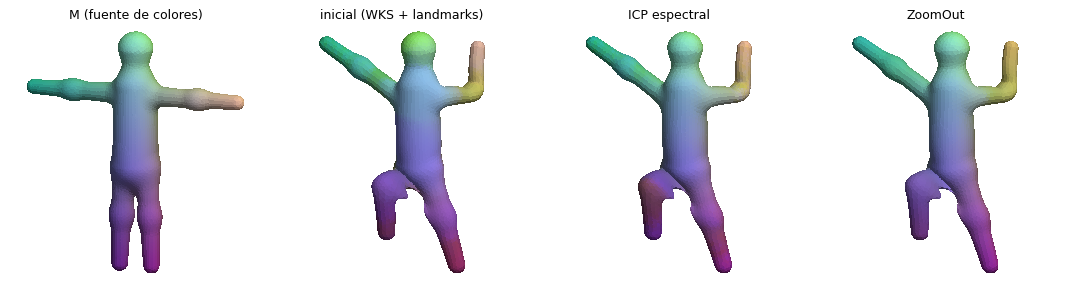

Exactitud de la segmentación transferida punto a punto:
  inicial (WKS + landmarks)    91.3%
  ICP espectral                96.3%
  ZoomOut                      92.0%
  cota: C verdad 120×120       98.7%


In [62]:
T_bound = pointwise_from_fmap(fmap_from_pointwise(T_gt, PhiM, PhiN, mN, KMAX), PhiM, PhiN)
maps = {'inicial (WKS + landmarks)': T_est['WKS + landmarks, μ=1e-2'], 'ICP espectral': T_icp,
        'ZoomOut': T_zo, f'cota: C verdad {KMAX}×{KMAX}': T_bound}
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
plot_error_curves(ev, maps, ax=axs[0], rmax=0.15)
axs[1].imshow(C_zo[:60, :60], cmap='RdBu_r', vmin=-1, vmax=1); axs[1].set_title('C de ZoomOut (primeras 60×60)')
plt.tight_layout(); plt.show()
show_maps(VM, FM, VN, FN, {k_: v for k_, v in maps.items() if not k_.startswith('cota')}, colM)
print('Exactitud de la segmentación transferida punto a punto:')
for name, T in maps.items():
    print(f'  {name:28s} {np.mean(labels_M[T] == labels_N_gt):.1%}')

ZoomOut baja mucho el error **mediano**, pero no el error en todas partes. Para ver dónde se
equivoca pintamos sobre $\mathcal N$ el error de cada vértice. Para que sea barato de calcular,
usamos como aproximación la distancia euclidiana, en la pose de reposo de $\mathcal M$, entre el
punto predicho y el correcto. También calculamos cuánto se **estira** la superficie de $\mathcal N$
al cambiar de pose alrededor de cada vértice (razón entre su área en la pose nueva y en reposo).

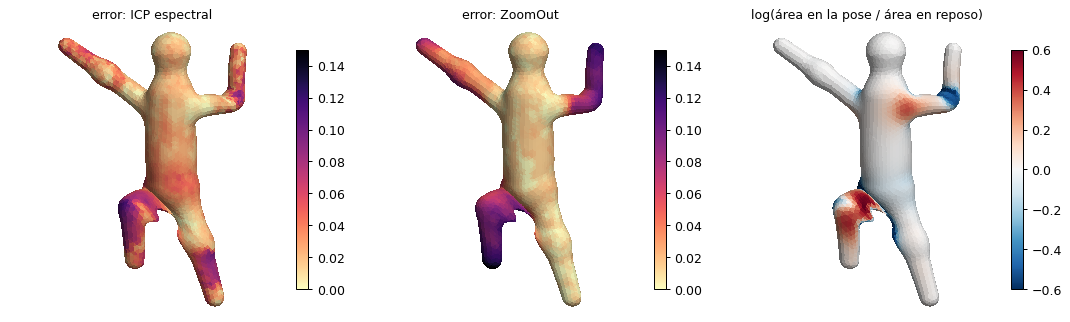

error mediano por parte (ICP | ZoomOut):
  spine   0.028 | 0.015
  head    0.015 | 0.012
  armL    0.015 | 0.039
  foreL   0.068 | 0.105
  thighL  0.023 | 0.014
  shinL   0.067 | 0.012
  armR    0.018 | 0.035
  foreR   0.044 | 0.071
  thighR  0.060 | 0.077
  shinR   0.059 | 0.159


In [63]:
err_field = lambda T: np.linalg.norm(VM[T] - VM[T_gt], axis=1) / ev.sqA
# estiramiento local: área de cada vértice de N en la pose nueva vs. en reposo (misma malla)
area_ratio = np.log(mN / mass_matrix(VN_rest, FN).diagonal())
fig, axs = plt.subplots(1, 3, figsize=(12, 4.5))
render(axs[0], VN, FN, err_field(T_icp), cmap='magma_r', vmin=0, vmax=0.15, view=(10, -25), title='error: ICP espectral', colorbar=True)
render(axs[1], VN, FN, err_field(T_zo), cmap='magma_r', vmin=0, vmax=0.15, view=(10, -25), title='error: ZoomOut', colorbar=True)
render(axs[2], VN, FN, area_ratio, cmap='RdBu_r', sym=True, vmax=0.6, view=(10, -25), title='log(área en la pose / área en reposo)', colorbar=True)
plt.tight_layout(); plt.show()
print('error mediano por parte (ICP | ZoomOut):')
lab_s = labels_N_gt[ev.s]; eI, eZ = ev.errors(T_icp), ev.errors(T_zo)
for l in np.unique(lab_s):
    m_ = lab_s == l
    print(f'  {names_parts[l]:7s} {np.median(eI[m_]):.3f} | {np.median(eZ[m_]):.3f}')

* En el torso, la cabeza y la pierna izquierda, ZoomOut deja el mapa al nivel de la cota: el error
  es del orden del tamaño de un triángulo, y todo con álgebra lineal densa de tamaño $k$ y búsquedas
  de vecino más cercano.
* Donde ZoomOut **no** mejora, o incluso empeora respecto del ICP, es en los brazos y la
  pierna derecha: son las extremidades que la pose de $\mathcal N$ dobla 70–90°, y el mapa de áreas
  muestra que ahí la superficie se comprime y se estira (nuestro *skinning* no es una isometría
  perfecta). Las frecuencias altas son las más sensibles a esa distorsión, y ZoomOut confía en
  ellas. El ICP, al quedarse en $k=20$ y forzar ortogonalidad, es más conservador.
* Moraleja: los refinamientos espectrales **suponen isometría**. Con formas reales (escaneos,
  personas distintas) eso se cumple sólo aproximadamente, y por eso existen variantes que relajan
  la ortogonalidad o trabajan con mapas parciales.

### ¿Y si los landmarks venían reflejados?

Corremos ZoomOut desde la $\mathbf C$ que se estimó con la **segunda** asignación del Ejercicio 2.

ZoomOut desde landmarks reflejados error mediano 0.264 | medio 0.358 | mediano módulo simetría 0.033


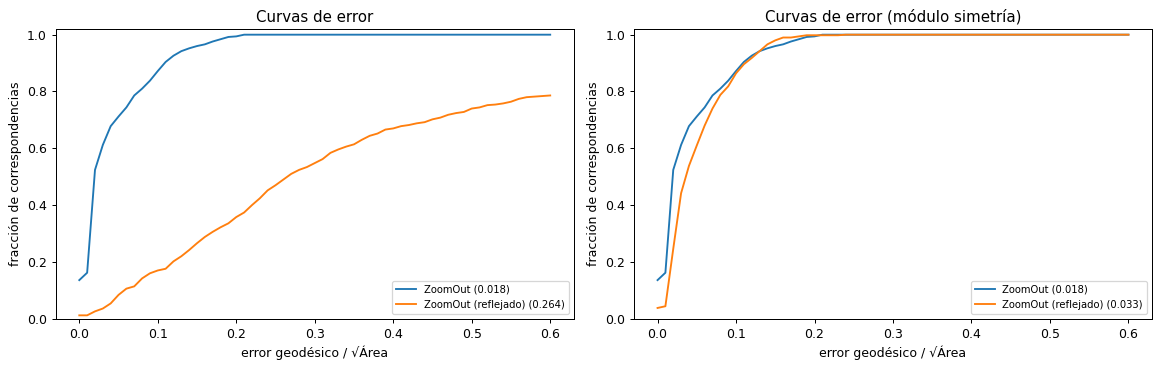

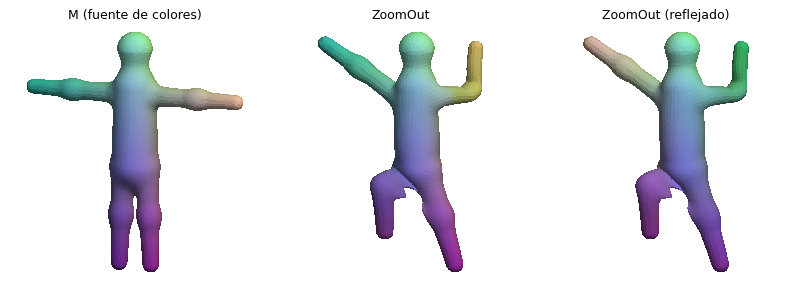

In [64]:
_, T_zo_flip = zoomout(C_est['WKS + landmarks (2.ª asig.)'], PhiM, PhiN, mN, KMAX, step=2)
ev.summary(T_zo_flip, 'ZoomOut desde landmarks reflejados')
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
plot_error_curves(ev, {'ZoomOut': T_zo, 'ZoomOut (reflejado)': T_zo_flip}, ax=axs[0], rmax=0.6)
plot_error_curves(ev, {'ZoomOut': T_zo, 'ZoomOut (reflejado)': T_zo_flip}, ax=axs[1], rmax=0.6, modulo_sym=True)
plt.tight_layout(); plt.show()
show_maps(VM, FM, VN, FN, {'ZoomOut': T_zo, 'ZoomOut (reflejado)': T_zo_flip}, colM)

El refinamiento **no corrige** la simetría: converge a un mapa tan preciso como el otro, pero
reflejado. ZoomOut (y el ICP) mejoran un mapa **dentro de su "cuenca"**: la inicialización decide
entre las soluciones isométricas.

---
# Bloque 6 — Todo junto en otra forma (10 min)

Encapsulamos el pipeline completo usando **sus** funciones:

1. espectros de ambas formas;
2. landmarks por muestreo del punto más lejano y su asignación por fuerza bruta (Ej. 2);
3. descriptores WKS + kernels de calor en los landmarks y $\mathbf C$ por mínimos cuadrados (Ej. 7);
4. ZoomOut (Ej. 9).

Lo probamos en el **cuadrúpedo**: $\mathcal M$ en reposo y $\mathcal N$ en otra pose, remallado.
Usamos 6 landmarks (4 patas, cabeza, cola): $6!=720$ permutaciones.

asignación n.º 1: costo 1.094 (mejor 1.094, segunda 1.236)
cuadrúpedo, 1.ª asignación       error mediano 0.214 | medio 0.245 | mediano módulo simetría 0.013
asignación n.º 2: costo 1.236 (mejor 1.094, segunda 1.236)
cuadrúpedo, 2.ª asignación       error mediano 0.012 | medio 0.017 | mediano módulo simetría 0.012
(18.6 s)


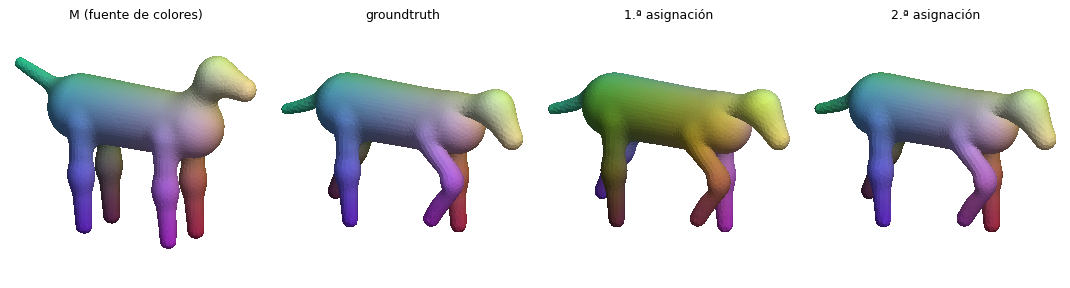

In [65]:
def match_shapes(VM, FM, VN, FN, n_landmarks=5, rank=0, k0=20, kmax=100, mu=1e-2, verbose=True):
    lamM, PhiM, _, MM = laplace_spectrum(VM, FM, kmax); lamN, PhiN, _, MN = laplace_spectrum(VN, FN, kmax)
    mM, mN = MM.diagonal(), MN.diagonal()
    lM, lN = farthest_point_sampling(VM, FM, n_landmarks), farthest_point_sampling(VN, FN, n_landmarks)
    rk = rank_permutations(geodesics_from(VM, FM, lM)[:, lM], geodesics_from(VN, FN, lN)[:, lN])
    cost, p = rk[rank]
    if verbose: print(f'asignación n.º {rank+1}: costo {cost:.3f} (mejor {rk[0][0]:.3f}, segunda {rk[1][0]:.3f})')
    A = coeffs(build_descriptors(lamM, PhiM, mM, lM), PhiM, mM, k0)
    B = coeffs(build_descriptors(lamN, PhiN, mN, lN[p]), PhiN, mN, k0)
    C0 = solve_fmap(A, B, lamM[:k0], lamN[:k0], mu)
    C, T = zoomout(C0, PhiM, PhiN, mN, kmax, step=2)
    return T, dict(lM=lM, lN=lN[p], cost=cost, C=C)

qb = quadruped_bones()
VQ, FQ = mesh_from_bones(qb, h=0.035)
VQ2_rest, FQ2 = mesh_from_bones(qb, h=0.042)
VQ2 = pose_mesh(VQ2_rest, qb, POSES['cuadrupedo'][1])
TQ_gt = cKDTree(VQ).query(VQ2_rest)[1]
evQ = MapEvaluator(VQ, FQ, VQ, TQ_gt, sym_axis=2)          # simetría izquierda/derecha: z -> -z
t0 = time.time()
TQ0, infoQ0 = match_shapes(VQ, FQ, VQ2, FQ2, n_landmarks=6, rank=0)
evQ.summary(TQ0, 'cuadrúpedo, 1.ª asignación')
TQ1, infoQ1 = match_shapes(VQ, FQ, VQ2, FQ2, n_landmarks=6, rank=1)
evQ.summary(TQ1, 'cuadrúpedo, 2.ª asignación')
print(f'({time.time()-t0:.1f} s)')
colQ = coord_colors(VQ)
show_maps(VQ, FQ, VQ2, FQ2, {'groundtruth': TQ_gt, '1.ª asignación': TQ0, '2.ª asignación': TQ1}, colQ,
          viewM=(15, -35), viewN=(15, -35))

Mira los dos errores de cada fila. Si una de las asignaciones da error grande pero error **módulo
simetría** pequeño, el pipeline encontró el mapa **reflejado** (patas izquierdas ↔ derechas): en
el cuadrúpedo la diferencia de costo entre la asignación correcta y la reflejada es pequeña, y
cualquier ruido decide cuál gana. Así se ve la simetría intrínseca en la práctica: el mapa es
**excelente** salvo por una reflexión global.

Cómo se rompe la simetría en la práctica:

* **Una anotación**: fijar a mano un solo par (por ejemplo, la pata delantera izquierda) reduce
  las permutaciones a las consistentes con ese par.
* **Información extrínseca orientada**: las isometrías que preservan la orientación no
  invierten la normal. Ren et al. (2018) agregan a la optimización de $\mathbf C$ un término
  que preserva el operador $f,g\mapsto\langle\nabla f\times\nabla g,\mathbf n\rangle$, que cambia de
  signo bajo reflexiones.
* **Aprendizaje**: los métodos neuronales aprenden descriptores que sí distinguen izquierda de
  derecha a partir de datos con la orientación correcta.

---
# Bloque 7 — Cierre (5 min)

| Representación | Tamaño | Restricciones | Optimización |
|---|---|---|---|
| Mapa punto a punto $T$ | $n_{\mathcal N}$ índices | distorsión geodésica | combinatoria, no convexa ($n!$) |
| Matriz $\boldsymbol\Pi$ | $n_{\mathcal N}\times n_{\mathcal M}$ | — | exacta pero gigantesca |
| **Mapa funcional $\mathbf C$** | $k\times k$ | descriptores, landmarks, conmutatividad: **lineales** | mínimos cuadrados |
| Conversión $\mathbf C\to T$ | — | vecino más cercano en $\mathbb R^k$ | — |
| Refinamiento | — | ortogonalidad (ICP) / crecimiento espectral (ZoomOut) | iterativo y barato |

### Preguntas para discutir

1. ¿Por qué $T_F$ va de funciones en $\mathcal M$ a funciones en $\mathcal N$ si $T$ va de $\mathcal N$ a $\mathcal M$? ¿Qué representaría $\mathbf C^\top$?
2. Si $\mathcal M$ y $\mathcal N$ fueran isométricas pero con un valor propio **doble** (como la estrella de la Clase 13), ¿qué forma tendría el bloque correspondiente de $\mathbf C$? ¿Sigue sirviendo la conmutatividad?
3. ¿Qué pasa con la estimación de $\mathbf C$ si los descriptores no son isométricamente invariantes (por ejemplo, las coordenadas $x,y,z$)?
4. El ICP espectral proyecta $\mathbf C$ a una matriz ortogonal y ZoomOut no. ¿Cuándo esperarías que la ortogonalidad sea una mala suposición? (Piensa en formas con distinta área local, o en formas **parciales**.)
5. ZoomOut nunca usa los descriptores después de la inicialización. ¿Qué información guía entonces la mejora?
6. Diseña una forma de romper la simetría izquierda/derecha usando sólo **un** landmark etiquetado.
7. ¿Qué cambiaría si una de las formas fuera una nube de puntos? ¿Qué parte del pipeline depende de tener una malla?

### Para seguir

* **pyFM** (`github.com/RobinMagnet/pyFM`): implementación completa en Python, con conmutatividad
  con operadores de descriptores (Nogneng y Ovsjanikov, 2017), ZoomOut y mallas reales (TOSCA, SHREC, FAUST).
* **Mapas funcionales profundos**: FMNet (Litany et al., 2017) aprende los descriptores y usa el
  bloque de mínimos cuadrados del Ejercicio 7 como una capa diferenciable; le siguen versiones no
  supervisadas (Halimi et al., 2019; Roufosse et al., 2019) y *Deep Geometric Functional Maps*
  (Donati et al., 2020) con DiffusionNet (Sharp et al., 2022).

### Bibliografía

* M. Ovsjanikov, M. Ben-Chen, J. Solomon, A. Butscher, L. Guibas. *Functional maps: a flexible representation of maps between shapes.* ACM TOG (SIGGRAPH), 2012.
* M. Ovsjanikov, E. Corman, M. Bronstein, E. Rodolà, M. Ben-Chen, L. Guibas, F. Chazal, A. Bronstein. *Computing and processing correspondences with functional maps.* Curso SIGGRAPH / Eurographics, 2016–2017.
* A. Bronstein, M. Bronstein, R. Kimmel. *Generalized multidimensional scaling: a framework for isometry-invariant partial surface matching.* PNAS, 2006.
* V. Kim, Y. Lipman, T. Funkhouser. *Blended intrinsic maps.* ACM TOG (SIGGRAPH), 2011.
* D. Nogneng, M. Ovsjanikov. *Informative descriptor preservation via commutativity for shape matching.* CGF (Eurographics), 2017.
* J. Ren, A. Poulenard, P. Wonka, M. Ovsjanikov. *Continuous and orientation-preserving correspondences via functional maps.* ACM TOG (SIGGRAPH Asia), 2018.
* S. Melzi, J. Ren, E. Rodolà, A. Sharma, P. Wonka, M. Ovsjanikov. *ZoomOut: spectral upsampling for efficient shape correspondence.* ACM TOG (SIGGRAPH Asia), 2019.
* O. Litany, T. Remez, E. Rodolà, A. Bronstein, M. Bronstein. *Deep functional maps: structured prediction for dense shape correspondence.* ICCV, 2017.
* N. Donati, A. Sharma, M. Ovsjanikov. *Deep geometric functional maps: robust feature learning for shape correspondence.* CVPR, 2020.
* N. Sharp, S. Attaiki, K. Crane, M. Ovsjanikov. *DiffusionNet: discretization agnostic learning on surfaces.* ACM TOG, 2022.